In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path

from magnetron.parameters import (
    GeometryParameters,
    MeshSettings,
    MagneticParameters,
)
from magnetron.geometry import MagnetronGeometry
from magnetron.mesh import MagnetronMesh
from magnetron.magnetostatic import MagnetostaticSimulation

In [3]:
results_dir = Path("../results/experiment")

geometry_parameters = GeometryParameters(
    target_diameter=0.0508,
    target_thickness=0.003,
    magnet_height=0.010,
    inner_magnet_diameter=0.018,
    outer_magnet_diameter=0.010,
    outer_magnet_ring_radius=0.022,
    magnet_to_target_distance=0.005,
    anode_cathode_gap=0.003,
    anode_width=0.004,
)

geometry = MagnetronGeometry(geometry_parameters)

mesh_path = MagnetronMesh(
    geometry,
    settings=MeshSettings(min_size=0.0001, max_size=0.001),
).generate(results_dir / "mesh.msh")

Info    : Meshing 1D...                                                                                                  
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 16 (Line)
Info    : [ 10%] Meshing curve 17 (Line)
Info    : [ 10%] Meshing curve 18 (Line)
Info    : [ 20%] Meshing curve 19 (Line)
Info    : [ 20%] Meshing curve 20 (Line)
Info    : [ 20%] Meshing curve 21 (Line)
Info    : [ 20%] Meshing curve 22 (Line)
Info    : [ 30%] Meshing curve 23 (Line)
Info    : [ 30%] Meshing curve 24 (Line)
Info    : [ 30%] Meshing curve 25 (Line)
Info    : [ 30%] Meshing curve 26 (Line)
Info    : [ 40%] Meshing curve 27 (Line)
Info    : [ 40%] Meshing curve 28 (Line)
Info    : [ 40%] Meshing curve 29 (Line)
Info    : [ 40%] Meshing curve 30 (Line)
Info    : [ 50%] Meshing curve 31 (Line)
Info    : [ 50%] Meshing curve 32 (Line)
Info    : [ 50%] Meshing curve 33 (Line)
Info    : [ 60%] Meshing curve 34 (Line)
Info    : [ 60%] Meshing curve 35 (Line)
Info    : [ 60%] 

In [4]:
magnetic_parameters = MagneticParameters(
    remanence=2.0,
    mu_r_air=1.0,
    mu_r_magnet=1.05,
    mu_r_backing=1.0,
)

result = MagnetostaticSimulation(
    mesh_path,
    magnetic_parameters,
).solve(results_dir)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 80 entities
Info    : 5945 nodes
Info    : 11608 elements
Info    : Done reading '../results/experiment/mesh.msh'
Mesh coordinate bounds [m]:
  x: -0.04 0.04
  y: -0.03 0.03
Magnetostatic problem solved.
Fields: ../results/experiment/fields.xdmf
Metadata: ../results/experiment/simulation.json
|B| min/max [T]: 0.0008733943956864965 1.605512660827556


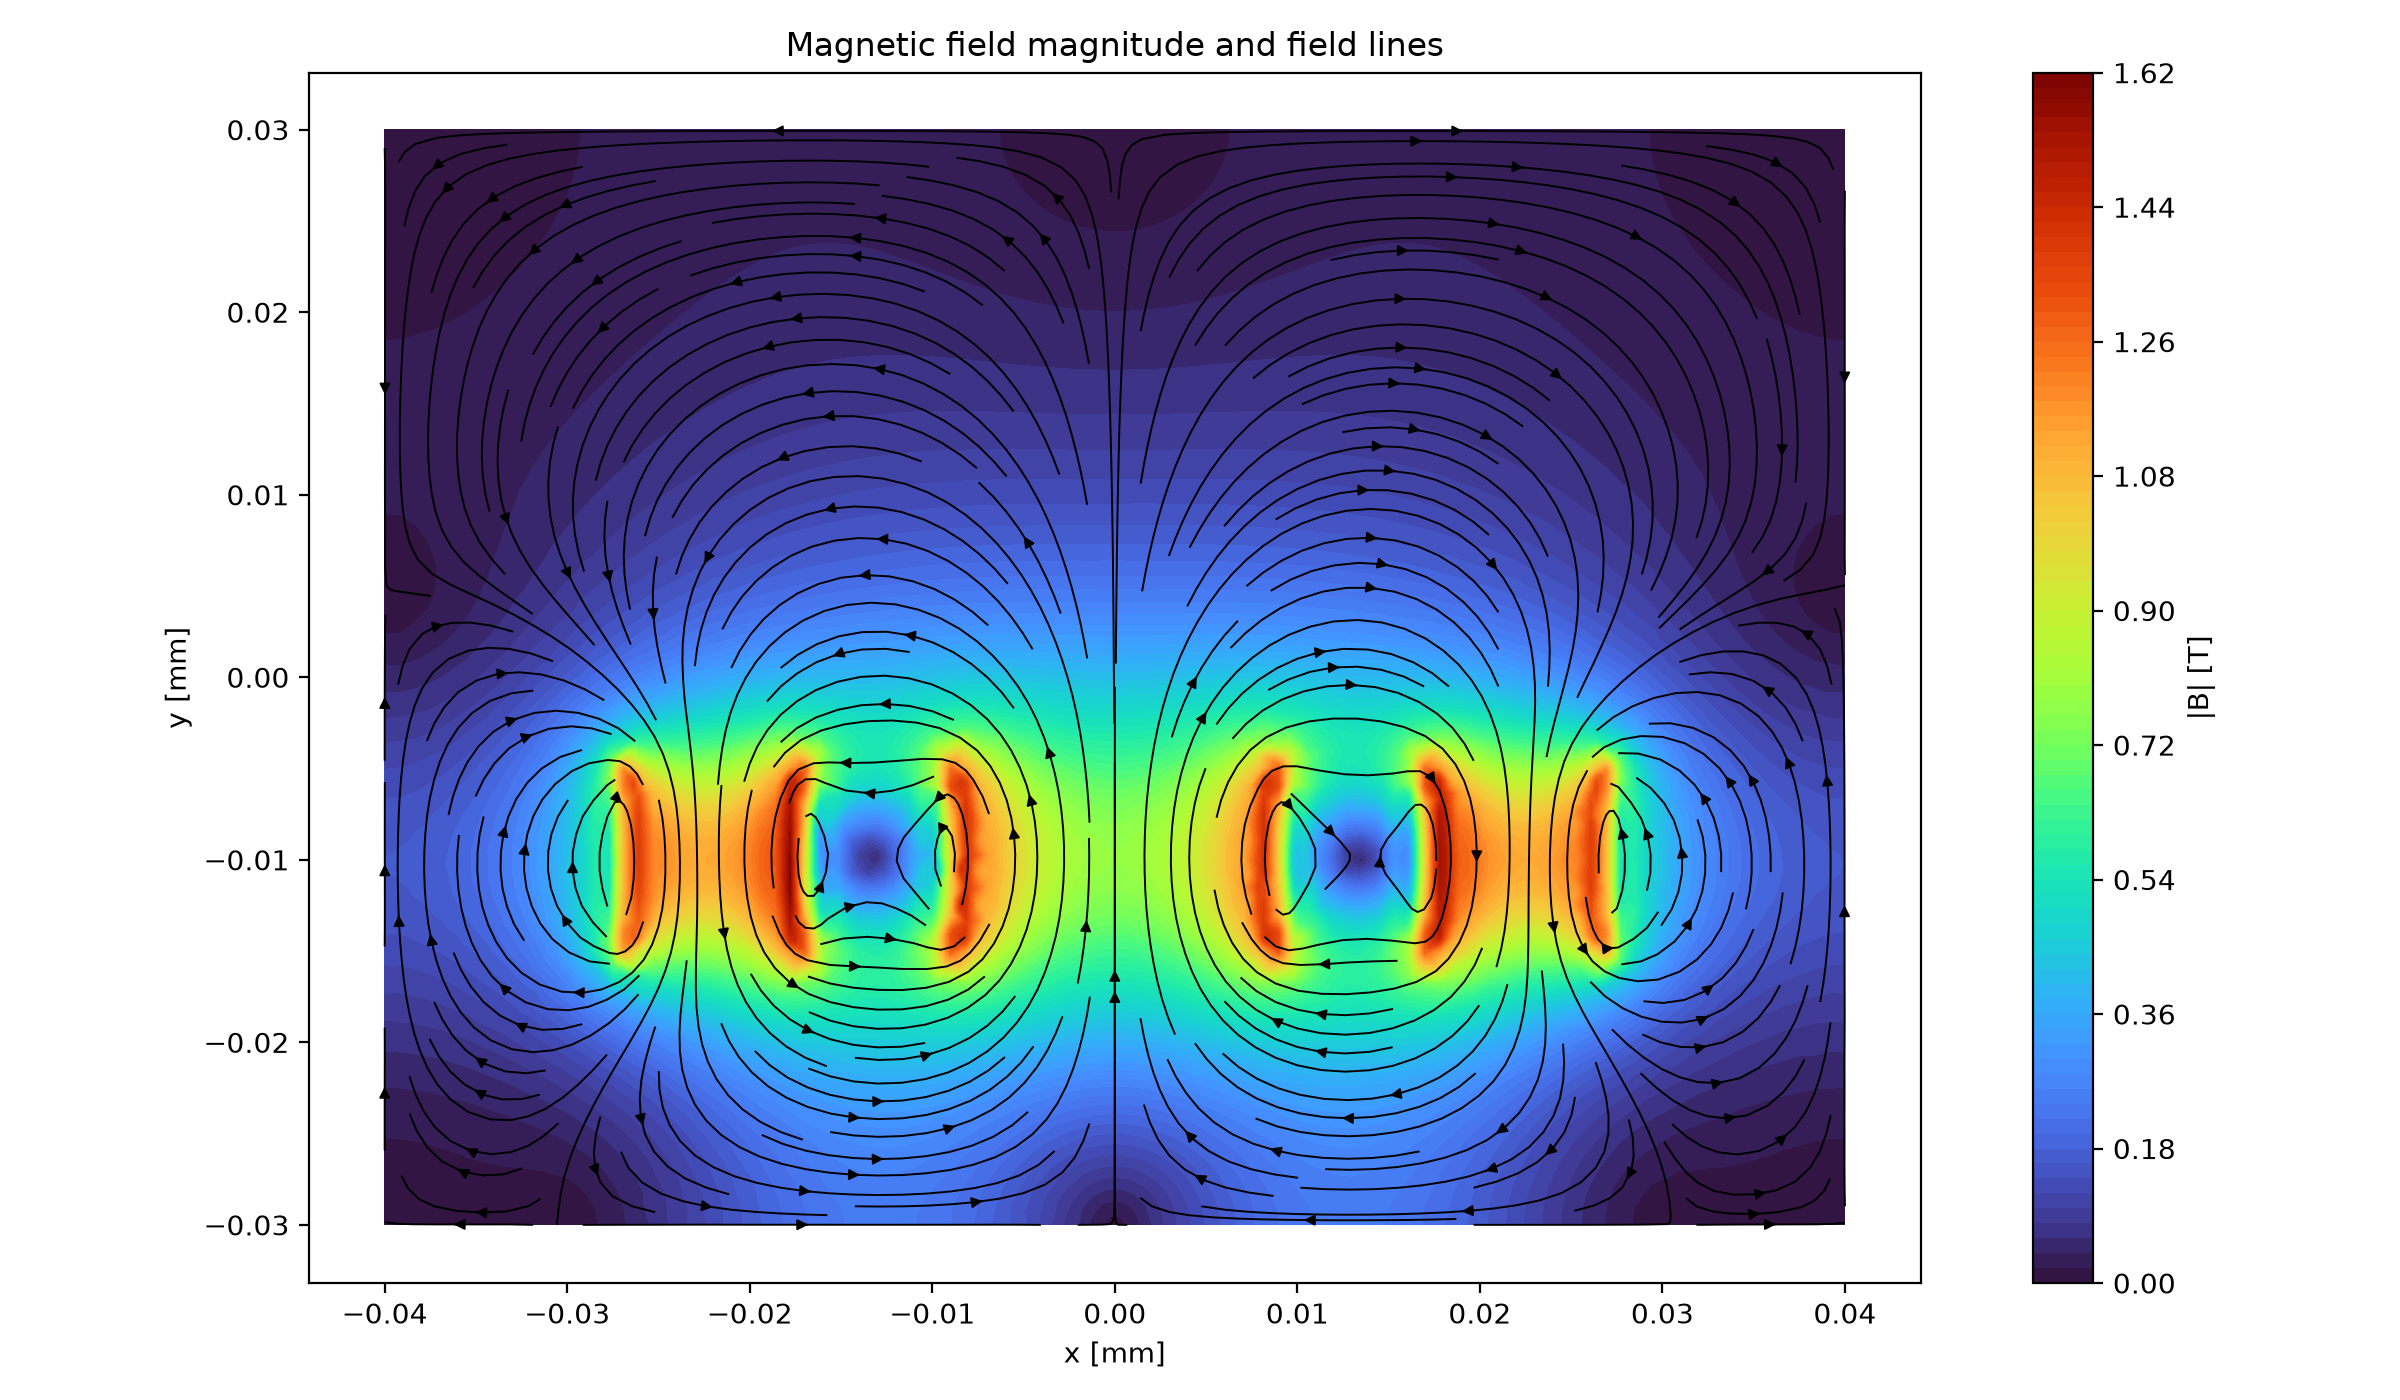

In [ ]:
from magnetron.visualization import plot_magnetic_field
from IPython.display import Image, display

field_plot_path = plot_magnetic_field(
    result,
    results_dir / "magnetic_field.png",
    target_diameter=geometry_parameters.target_diameter,
    target_thickness=geometry_parameters.target_thickness,
)

display(Image(filename=str(field_plot_path)))